# V6 — S4 một warp/query và shuffle top-2

V6 kế thừa V5, chỉ thay cách chia việc và tìm top-2 của S4. S1–S3, S5–S6 và dữ liệu trung gian trên GPU giữ nguyên.

Mỗi warp xử lý một query, dùng shared-memory tile 128 descriptor B và shuffle reduction để tìm top-2. Ratio test, cross-check, tie-break và thứ tự matches không đổi.

## 1. Môi trường và build

Chọn Colab GPU, sau đó Run all. Notebook clone nhánh `v6`; đặt `USE_EXISTING_SOURCE=True` khi dùng checkout có sẵn.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
import os, sys, shlex, subprocess, json
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image as PILImage
from IPython.display import display, Markdown, HTML, Code

REPO_URL = 'https://github.com/nganbee/panorama-stitching-project.git'
BRANCH = 'v6'
REPO_DIR = Path('/content/panorama-stitching-project')
USE_EXISTING_SOURCE = False

def run(command, check=True):
    args = shlex.split(command) if isinstance(command,str) else [str(x) for x in command]
    print('$',shlex.join(args),flush=True)
    with subprocess.Popen(args,stdout=subprocess.PIPE,stderr=subprocess.STDOUT,text=True,bufsize=1) as process:
        for line in process.stdout:
            print(line,end='',flush=True)
        status = process.wait()
    if check and status:
        raise RuntimeError(f'Command failed with exit code {status}; inspect its output.')
    return status

if USE_EXISTING_SOURCE:
    assert REPO_DIR.is_dir(), 'Upload source and set REPO_DIR first.'
elif not REPO_DIR.exists():
    run(['git','clone','--branch',BRANCH,REPO_URL,REPO_DIR])
else:
    run(['git','-C',REPO_DIR,'fetch','origin',BRANCH])
    run(['git','-C',REPO_DIR,'checkout',BRANCH])
    run(['git','-C',REPO_DIR,'pull','--ff-only','origin',BRANCH])
os.chdir(REPO_DIR)
TOOLS_DIR = next((p for p in [Path('src/tools/v6'),Path('tools/v6')]
                  if (p/'build.sh').is_file()),None)
assert TOOLS_DIR is not None, 'Missing V6 tools.'
print('V6 tools:',TOOLS_DIR)
GPU_NAME = subprocess.check_output(['nvidia-smi','--query-gpu=name',
    '--format=csv,noheader'],text=True).strip()
print('GPU:',GPU_NAME)
run('nvidia-smi')
run('nvcc --version')
run('g++ --version')
run('git rev-parse HEAD',check=False)

sites = ['location1','location2','location3','challenge']
sizes = {'small_720p':(1280,720),'medium_1080p':(1920,1080),'large_4k':(3840,2160)}
for site in sites:
    for size,expected in sizes.items():
        for name in ['1.jpg','2.jpg']:
            path = Path('dataset')/site/size/name
            assert path.is_file(), f'Missing input: {path}'
            with PILImage.open(path) as image:
                assert image.size == expected, (str(path),image.size,expected)
print('Dataset ready:',len(sites)*len(sizes),'cases')

$ git clone --branch v6 https://github.com/nganbee/panorama-stitching-project.git /content/panorama-stitching-project
Cloning into '/content/panorama-stitching-project'...
V6 tools: src/tools/v6
GPU: Tesla T4
$ nvidia-smi
Sat Nov 28 04:59:13 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   37

### 1.1. Build và tham số chung


In [2]:
run(['bash',TOOLS_DIR/'build.sh'])
run('build/stitch_v6 --list-versions')
params = json.loads(subprocess.check_output(['build/stitch_v6','--dump-params'],text=True))
display(pd.DataFrame([params]))
assert all(v in params['available_versions'] for v in [0,5,6])


$ bash src/tools/v6/build.sh
$ build/stitch_v6 --list-versions
0
1
2
3
4
5
6


,schema_version,kGaussSigma,kGaussRadius,kHarrisK,kHarrisThresh,kHarrisWinRadius,kNmsRadius,kTopK,kBorder,kPatchSize,kBriefSeed,kRatio,kRansacIters,kRansacThresh,kRansacSeed,available_versions
0,1,1.4,4,0.04,0.01,2,2,3000,16,31,12345,0.8,2000,3,2026,"[0, 1, 2, 3, 4, 5, 6]"


## 2. Bottleneck V5

Đo V0 và V5 trên cùng bộ ảnh để có baseline trong **chính phiên Colab GPU này**. Dùng timing từng stage của V5 để xác định S4 có đáng tối ưu; không suy bottleneck GPU từ thời gian CPU V0. Bảng dưới giữ S1–S6, tổng kernel, H2D, D2H và end-to-end để không bỏ qua chi phí truyền dữ liệu.

**Phương pháp đo dùng chung:** mỗi case/version chạy một warm-up, sau đó năm lần đo và báo cáo trung bình. GPU stage/copy dùng CUDA events trong pipeline; end-to-end bao gồm allocation, launch, đồng bộ và truyền dữ liệu, loại đọc/ghi ảnh. Lưu từng lần đo và minimum để xem thêm khi dao động lớn. Không cộng kernel/copy vào end-to-end lần nữa.

Dataset gồm ba cặp chuẩn và một cặp khó, mỗi cặp có ba độ phân giải: 720p, 1080p và 4K. Các version dùng cùng ảnh, tham số và cấu hình build. Giữ nguyên GPU/runtime trong suốt notebook; nếu đổi runtime, chạy lại từ đầu để không trộn số liệu.

In [3]:
print('GPU:',GPU_NAME)
RUN_DIR = Path('reports/v6_benchmark')/datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
run([sys.executable,TOOLS_DIR/'benchmark.py','--phase','baseline','--run-dir',RUN_DIR])
baseline = pd.read_csv(RUN_DIR/'summary.csv')
columns = ['case']+[f'v5_S{i}_ms' for i in range(1,7)]+[
    'v5_kernel_total_ms','v5_h2d_ms','v5_d2h_ms','v5_end_to_end_ms','v5_S4_kernel_share']
display(baseline.reindex(columns=columns))
print('Units: ms; S4 share is relative to GPU kernel_total, not end-to-end.')

GPU: Tesla T4
$ /usr/bin/python3 src/tools/v6/benchmark.py --phase baseline --run-dir reports/v6_benchmark/20261128T050247957349Z
Tesla T4, GPU-0df25115-db07-2b9d-fde4-7864fad974f8, 580.82.07

baseline location1_small_720p
baseline location1_medium_1080p
baseline location1_large_4k
baseline location2_small_720p
baseline location2_medium_1080p
baseline location2_large_4k
baseline location3_small_720p
baseline location3_medium_1080p
baseline location3_large_4k
baseline challenge_small_720p
baseline challenge_medium_1080p
baseline challenge_large_4k
Saved: reports/v6_benchmark/20261128T050247957349Z/summary.csv
Statuses: {'location1_small_720p': 'baseline_only', 'location1_medium_1080p': 'baseline_only', 'location1_large_4k': 'baseline_only', 'location2_small_720p': 'baseline_only', 'location2_medium_1080p': 'baseline_only', 'location2_large_4k': 'baseline_only', 'location3_small_720p': 'baseline_only', 'location3_medium_1080p': 'baseline_only', 'location3_large_4k': 'baseline_only', 'cha

,case,v5_S1_ms,v5_S2_ms,v5_S3_ms,v5_S4_ms,v5_S5_ms,v5_S6_ms,v5_kernel_total_ms,v5_h2d_ms,v5_d2h_ms,v5_end_to_end_ms,v5_S4_kernel_share
0,location1_small_720p,0.402586,1.335213,0.368179,0.594912,16.247277,6.824870,25.773037,1.440403,1.474624,37.077876,0.023083
1,location1_medium_1080p,0.700608,2.248800,0.392954,0.732685,17.750413,12.276672,34.102131,3.008755,3.044928,52.834087,0.021485
2,location1_large_4k,1.914547,5.725402,0.768749,0.729594,14.387769,34.548941,58.075001,14.149133,12.025536,124.442169,0.012563
3,location2_small_720p,0.383475,1.258963,0.348141,0.692198,13.659520,5.867552,22.209850,1.327987,1.267565,31.267010,0.031166
4,location2_medium_1080p,0.674253,2.178528,0.445542,0.907782,12.235481,9.776563,26.218150,2.909306,2.568224,42.137439,0.034624
5,location2_large_4k,2.105395,6.362310,0.966336,0.781728,8.866362,23.807392,42.889523,14.513542,12.629024,112.559758,0.018227
6,location3_small_720p,0.428870,1.281363,0.372352,0.111437,10.902419,7.764333,20.860774,1.301882,1.197043,29.862184,0.005342
7,location3_medium_1080p,0.720160,2.209843,0.339846,0.201126,8.302970,11.035034,22.808979,2.946291,2.574458,39.923987,0.008818
8,location3_large_4k,2.069830,6.098048,0.484800,0.492627,6.410067,30.269747,45.825120,14.479834,12.604647,113.131293,0.010750
9,challenge_small_720p,0.395200,1.269824,0.366669,0.376422,10.632499,10.576973,23.617587,1.329677,1.393658,34.078998,0.015938


Units: ms; S4 share is relative to GPU kernel_total, not end-to-end.


### Bằng chứng profiling V5

Thu Nsight Systems hoặc Nsight Compute cho case có S4 V5 lâu nhất trong baseline. Hiện output thật của `nearest_tiled_kernel` cùng các kernel còn lại để đối chiếu tỷ trọng S4. Nếu không thu được, giữ trạng thái thiếu bằng chứng.

Thời gian trong profiler chỉ phục vụ phân tích, không thay số đo benchmark. Có thể gọi `profile.py --version 6` riêng sau benchmark khi cần đối chiếu `nearest_warp_kernel`.


In [4]:
run([sys.executable,TOOLS_DIR/'profile.py','--run-dir',RUN_DIR,'--version','5'])
profile_v5 = json.loads((RUN_DIR/'profiling/profile_v5.json').read_text(encoding='utf-8'))
print('Profiling:',profile_v5['status'])
if profile_v5['status']=='collected':
    print('Case:',profile_v5['case'],'| tool:',profile_v5['tool'])
    print('Report:',profile_v5['report'])
    print(Path(profile_v5['summary']).read_text(encoding='utf-8',errors='replace'))
else:
    print('Profiling evidence is missing; retain actual logs and collect it in a supported environment.')

$ /usr/bin/python3 src/tools/v6/profile.py --run-dir reports/v6_benchmark/20261128T050247957349Z --version 5
$ nsys profile --trace=cuda --sample=none --cpuctxsw=none --force-overwrite=true -o reports/v6_benchmark/20261128T050247957349Z/profiling/location2_medium_1080p_v5 build/benchmark_v6_pair dataset/location2/medium_1080p/1.jpg dataset/location2/medium_1080p/2.jpg reports/v6_benchmark/20261128T050247957349Z/profiling/location2_medium_1080p_v5.png 5 5 reports/v6_benchmark/20261128T050247957349Z/profiling/location2_medium_1080p_v5_diagnostic_timing.json
GPU: Tesla T4 version=5 runs=5
Generating '/tmp/nsys-report-fb8d.qdstrm'

[1/1] [0%                          ] location2_medium_1080p_v5.nsys-rep
[1/1] [0%                          ] location2_medium_1080p_v5.nsys-rep
[1/1] [===================81%      ] location2_medium_1080p_v5.nsys-rep
[1/1] [========================100%] location2_medium_1080p_v5.nsys-rep
[1/1] [========================100%] location2_medium_1080p_v5.nsys-rep
Gene

## 3. Ý tưởng tối ưu

V5 dùng một thread/query và shared-memory tiling. V6 chia một query cho 32 lane: lane `l` so candidate `l, l+32, l+64, …`, giữ top-2 cục bộ rồi gộp bằng shuffle reduction.

V6 giữ shared-memory tiling kế thừa V2 qua V5: mỗi tile chứa 128 descriptor B và được bốn query trong block dùng chung. So với V5, thay đổi chính là một warp cùng xử lý một query và reduction top-2. Đo riêng S4 và end-to-end trên cùng bộ ảnh để đánh giá lợi ích của cách chia việc này.


## 4. Cách triển khai

```text
S1–S3 [V5, device-resident]
 → S4 [V6: warp/query, shared-memory tile, shuffle top-2]
 → S5–S6 [V5, device-resident] → panorama
```

- 128 thread/block, bốn warp xử lý bốn query.
- Cả block nạp tile 128 descriptor B vào shared memory. Trong tile, lane `l` so các candidate `l, l+32, l+64, …`; bốn query dùng chung tile. Hai lần `__syncthreads()` bảo đảm nạp xong trước khi đọc và đọc xong trước khi thay tile.
- Giữ hai khóa tốt nhất theo `(distance, candidate index)` trong mỗi lane. Shuffle qua các bước 16, 8, 4, 2, 1 gộp top-2; lane 0 ghi kết quả.
- Candidate bằng khoảng cách vẫn được phân biệt theo index; index nhỏ nhất thắng. Thiếu second neighbour thì giữ sentinel 257.
- Warp không có query ở block cuối vẫn tham gia cả hai block barrier và shuffle với sentinel; không đọc query/candidate ngoài biên.
- Giữ ratio test, reverse cross-check, ordered compaction và giao diện device V5. Cả hai chiều matching dùng cùng kernel V6.

Cell dưới hiển thị kernel từ file source dùng để biên dịch.


In [5]:
source = Path('src/stage_implementations/v6_stage4.cu').read_text(encoding='utf-8')
begin = source.index('// Sort by')
end = source.index('__global__ void filter_kernel',begin)
display(Code(source[begin:end],language='cuda'))

// Sort by (Hamming distance, candidate index). Equal distances at distinct
// indices occupy both top slots, exactly as the ascending V0/V5 scan does.
using Key = unsigned long long;
__device__ void insert_key(Key value, Key& first, Key& second) {
    if (value < first) { second = first; first = value; }
    else if (value != first && value < second) second = value;
}

// Four queries/block. All threads, including inactive final warps, reach
// both block barriers. Every shuffle has all 32 lanes participating.
__global__ void nearest_warp_kernel(const Descriptor* query, int nq,
                                    const Descriptor* candidates, int nc,
                                    int* best, int* first, int* second) {
    __shared__ Descriptor tile[128];
    const int lane = threadIdx.x & 31;
    const size_t i = static_cast<size_t>(blockIdx.x) * 4 + threadIdx.x / 32;
    const bool active = i < static_cast<size_t>(nq);
    Descriptor q{};
    if (active) q = query[i];
    Key d1 = ~Key{0}, d2 = ~Key{0};
    for (size_t base = 0; base < static_cast<size_t>(nc); base += 128) {
        const size_t j = base + threadIdx.x;
        if (j < static_cast<size_t>(nc)) tile[threadIdx.x] = candidates[j];
        __syncthreads();
        const size_t remaining = static_cast<size_t>(nc) - base;
        const int length = remaining < 128 ? static_cast<int>(remaining) : 128;
        if (active) {
            for (int k = lane; k < length; k += 32) {
                const Key key = (static_cast<Key>(distance(q,tile[k])) << 32) |
                                static_cast<unsigned int>(base+k);
                insert_key(key,d1,d2);
            }
        }
        __syncthreads();
    }
    for (int offset = 16; offset > 0; offset /= 2) {
        const Key other1 = __shfl_down_sync(0xffffffffu,d1,offset);
        const Key other2 = __shfl_down_sync(0xffffffffu,d2,offset);
        if (lane+offset < 32) {
            insert_key(other1,d1,d2);
            insert_key(other2,d1,d2);
        }
    }
    if (active && lane == 0) {
        best[i] = d1 == ~Key{0} ? -1 : static_cast<int>(static_cast<unsigned int>(d1));
        if (first) first[i] = d1 == ~Key{0} ? 257 : static_cast<int>(d1 >> 32);
        if (second) second[i] = d2 == ~Key{0} ? 257 : static_cast<int>(d2 >> 32);
    }
}

## 5. Kiểm chứng và benchmark

### 5.1. Tiêu chí kiểm chứng

Test S4 kiểm tra trực tiếp nearest index, best/second-best trước filter so với quét CPU, rồi so ordered matches V0/V5/V6 trên cùng descriptor. Bao gồm input rỗng, một candidate, ratio boundary, cross-check, ties khác lane và stride và query count không chia hết bốn.

Test pipeline so V6 với V0 theo dung sai nhóm: ordered matches và inlier trùng; sai số chiếu homography ≤`1e-3 px`; panorama cùng kích thước, RGB lệch tối đa 1 mức, kèm MAE. V5/V6 phải trùng chính xác homography, matches và panorama. Test tổng hợp còn kiểm tra byte copy giữ nguyên V5.

Verifier ảnh thật tái sử dụng extraction V1 được kế thừa để cấp cùng descriptor cho ba matcher, rồi kiểm tra pipeline V0/V5/V6. Verification nằm ngoài timing. Hai bản cùng thất bại được ghi status, không coi là panorama PASS và không tính speedup thành công.


### 5.2. Self-test S4

Đối chiếu matcher V0/V5/V6 trên cùng descriptor.

Test kiểm tra cả top-2 trước filter để không che lỗi reduction khi ratio test loại match.


In [6]:
run('build/stage4_v6_selftest')


$ build/stage4_v6_selftest
PASS: S4 V0/V5/V6 ordered matching, shared-tile warp top-2, ratio and cross-check


0

### 5.3. Self-test toàn pipeline


In [7]:
run('build/test_v6_pipeline')


$ build/test_v6_pipeline
  panorama MAE vs V0=0.000000000
PASS: V6 pipeline matches V0/V5; residency unchanged
  panorama MAE vs V0=0.000000000
PASS: V6 pipeline matches V0/V5; residency unchanged
  panorama MAE vs V0=0.000000000
PASS: V6 pipeline matches V0/V5; residency unchanged
PASS: V6 expected error cases


0

### 5.4. Kiểm chứng và đo V0/V5/V6

Baseline mục 2 dùng chọn hướng tối ưu và được giữ riêng. Kết quả so sánh mới lưu trong `RUN_DIR/comparison/`.

Mỗi case được kiểm chứng trước khi đo. V0 chạy riêng trong cùng session, dùng `std::chrono::high_resolution_clock`. V5/V6 dùng chung một process, CUDA context và hai ảnh đã nạp vào RAM. Warm-up mỗi bản một lần, sau đó đo năm vòng; mỗi vòng chạy cả V5 và V6, đảo bản chạy trước ở vòng kế tiếp. Như vậy mỗi bản có năm mẫu; một bản đứng trước ba lần, bản kia hai lần. Bản bắt đầu được đổi ở case kế tiếp.

Raw samples và vị trí từng mẫu được lưu trong report. `<case>_paired.json` ghi thứ tự toàn bộ lượt đo; script chỉ tính speedup khi các report khớp cùng lượt đo xen kẽ. Đọc/ghi ảnh và verification nằm ngoài timing. Dùng `RUN_DIR` mới cho mỗi lần chạy.


In [8]:
benchmark_status = run([sys.executable,TOOLS_DIR/'benchmark.py','--phase','optimized',
                        '--run-dir',RUN_DIR],check=False)
RESULT_DIR = RUN_DIR/'comparison'
summary = pd.read_csv(RESULT_DIR/'summary.csv')
verification_columns = ['case','status','failed_checks','V0_V6_projection_error_px',
    'V0_V6_pixel_max_error','V0_V6_pixel_mae','V5_V6_projection_error_px','V5_V6_pixel_max_error']
display(summary.reindex(columns=verification_columns))
print('Process status:',benchmark_status,'| Reports/logs:',RESULT_DIR)

$ /usr/bin/python3 src/tools/v6/benchmark.py --phase optimized --run-dir reports/v6_benchmark/20261128T050247957349Z
Tesla T4, GPU-0df25115-db07-2b9d-fde4-7864fad974f8, 580.82.07

optimized location1_small_720p
optimized location1_medium_1080p
optimized location1_large_4k
optimized location2_small_720p
optimized location2_medium_1080p
optimized location2_large_4k
optimized location3_small_720p
optimized location3_medium_1080p
optimized location3_large_4k
optimized challenge_small_720p
optimized challenge_medium_1080p
optimized challenge_large_4k
Saved: reports/v6_benchmark/20261128T050247957349Z/comparison/summary.csv
Statuses: {'location1_small_720p': 'pass', 'location1_medium_1080p': 'pass', 'location1_large_4k': 'pass', 'location2_small_720p': 'pass', 'location2_medium_1080p': 'pass', 'location2_large_4k': 'pass', 'location3_small_720p': 'pass', 'location3_medium_1080p': 'pass', 'location3_large_4k': 'pass', 'challenge_small_720p': 'pass', 'challenge_medium_1080p': 'pass', 'challeng

,case,status,failed_checks,V0_V6_projection_error_px,V0_V6_pixel_max_error,V0_V6_pixel_mae,V5_V6_projection_error_px,V5_V6_pixel_max_error
0,location1_small_720p,pass,NaN,0,1,0.000003,0,0
1,location1_medium_1080p,pass,NaN,0,1,0.000004,0,0
2,location1_large_4k,pass,NaN,0,1,0.000004,0,0
3,location2_small_720p,pass,NaN,0,1,0.000005,0,0
4,location2_medium_1080p,pass,NaN,0,1,0.000005,0,0
5,location2_large_4k,pass,NaN,0,1,0.000006,0,0
6,location3_small_720p,pass,NaN,0,1,0.000006,0,0
7,location3_medium_1080p,pass,NaN,0,1,0.000004,0,0
8,location3_large_4k,pass,NaN,0,1,0.000003,0,0
9,challenge_small_720p,pass,NaN,0,1,0.000005,0,0


Process status: 0 | Reports/logs: reports/v6_benchmark/20261128T050247957349Z/comparison


### Thứ tự đo V5/V6

Bảng dưới xác nhận mỗi case có năm mẫu/version và thứ tự đo trong cùng process.


In [9]:
protocol_rows = []
for case in summary['case']:
    path = RESULT_DIR/f'{case}_paired.json'
    record = json.loads(path.read_text(encoding='utf-8')) if path.is_file() else {}
    protocol_rows.append({'case':case,'status':record.get('status','missing'),
        'mode':record.get('measurement_mode'), 'samples/version':record.get('runs_per_version'),
        'warmups/version':record.get('warmup_runs_per_version'),'order':record.get('order')})
display(pd.DataFrame(protocol_rows))


,case,status,mode,samples/version,warmups/version,order
0,location1_small_720p,ok,same_process_interleaved,5,1,"[5, 6, 6, 5, 5, 6, 6, 5, 5, 6]"
1,location1_medium_1080p,ok,same_process_interleaved,5,1,"[6, 5, 5, 6, 6, 5, 5, 6, 6, 5]"
2,location1_large_4k,ok,same_process_interleaved,5,1,"[5, 6, 6, 5, 5, 6, 6, 5, 5, 6]"
3,location2_small_720p,ok,same_process_interleaved,5,1,"[6, 5, 5, 6, 6, 5, 5, 6, 6, 5]"
4,location2_medium_1080p,ok,same_process_interleaved,5,1,"[5, 6, 6, 5, 5, 6, 6, 5, 5, 6]"
5,location2_large_4k,ok,same_process_interleaved,5,1,"[6, 5, 5, 6, 6, 5, 5, 6, 6, 5]"
6,location3_small_720p,ok,same_process_interleaved,5,1,"[5, 6, 6, 5, 5, 6, 6, 5, 5, 6]"
7,location3_medium_1080p,ok,same_process_interleaved,5,1,"[6, 5, 5, 6, 6, 5, 5, 6, 6, 5]"
8,location3_large_4k,ok,same_process_interleaved,5,1,"[5, 6, 6, 5, 5, 6, 6, 5, 5, 6]"
9,challenge_small_720p,ok,same_process_interleaved,5,1,"[6, 5, 5, 6, 6, 5, 5, 6, 6, 5]"


## 6. Timing, speedup và panorama

### 6.1. Bảng thời gian

Bảng chính tập trung **S4** và **end-to-end**. Mỗi ô thời gian hiển thị **mean (minimum)**, đơn vị ms. Báo cáo đồng thời `T_V0/T_V6` và `T_V5/T_V6`; lớn hơn 1 là nhanh hơn, nhỏ hơn 1 là chậm hơn. S4 GPU là kernel time, còn end-to-end thể hiện lợi ích toàn chương trình.

Timing từng stage, tổng kernel và H2D/D2H vẫn được báo cáo trong bảng chi tiết có thể mở bên dưới và lưu CSV. Không vẽ lại nhiều biểu đồ từ cùng một bộ số liệu. Raw samples và mọi status được giữ trong JSON/log để kiểm tra khi cần.
Các cột `saved ms` tính V5 − V6: dương là giảm thời gian. `Remaining E2E delta` là phần chênh end-to-end ngoài delta S4; đối chiếu với bảng stage/copy bên dưới, không mặc định coi phần này là lợi ích của warp/query hay chỉ là nhiễu.


In [10]:
print('GPU:',GPU_NAME)
valid = summary[summary.status=='pass'].copy()
result_rows = []
for _,row in valid.iterrows():
    entry = {'case':row['case']}
    for metric,label in [('match','S4'),('end_to_end','E2E')]:
        for version in [0,5,6]:
            mean,minimum = row[f'v{version}_{metric}_ms'],row[f'v{version}_{metric}_min_ms']
            entry[f'{label} V{version}: mean (min) ms'] = f'{mean:.3f} ({minimum:.3f})'
        entry[f'{label} V0/V6'] = row[f'v0_over_v6_{metric}_speedup']
        entry[f'{label} V5/V6'] = row[f'v5_over_v6_{metric}_speedup']
    entry['S4 saved ms (V5-V6)'] = row['v5_match_ms']-row['v6_match_ms']
    entry['E2E saved ms (V5-V6)'] = row['v5_end_to_end_ms']-row['v6_end_to_end_ms']
    entry['Remaining E2E delta ms'] = entry['E2E saved ms (V5-V6)']-entry['S4 saved ms (V5-V6)']
    result_rows.append(entry)
display(pd.DataFrame(result_rows))

stage_rows = []
for _,row in summary.iterrows():
    for version in [0,5,6]:
        entry = {'case':row['case'],'version':version,'status':row['status']}
        for metric in ['S1','S2','S3','S4','S5','S6','kernel_total','h2d','d2h','end_to_end']:
            entry[metric+' ms'] = row.get(f'v{version}_{metric}_ms')
        stage_rows.append(entry)
stage_comparison = pd.DataFrame(stage_rows)
stage_comparison.to_csv(RESULT_DIR/'stage_comparison.csv',index=False)
display(HTML('<details><summary>Timing chi tiết từng stage, kernel, H2D/D2H và end-to-end (ms)</summary>'
             +stage_comparison.to_html(index=False)+'<p>V0 CPU không có kernel/H2D/D2H; các trường này bằng 0.</p></details>'))

GPU: Tesla T4


,case,S4 V0: mean (min) ms,S4 V5: mean (min) ms,S4 V6: mean (min) ms,S4 V0/V6,S4 V5/V6,E2E V0: mean (min) ms,E2E V5: mean (min) ms,E2E V6: mean (min) ms,E2E V0/V6,E2E V5/V6,S4 saved ms (V5-V6),E2E saved ms (V5-V6),Remaining E2E delta ms
0,location1_small_720p,745.737 (730.013),0.391 (0.356),0.329 (0.256),2264.750121,1.187697,1145.730 (1119.944),26.618 (24.424),26.088 (21.100),43.917550,1.020311,0.061805,0.529872,0.468067
1,location1_medium_1080p,1731.762 (1683.031),0.531 (0.433),0.547 (0.451),3166.547387,0.971481,2733.925 (2566.436),42.513 (34.471),40.568 (34.641),67.391167,1.047937,-0.015597,1.944722,1.960319
2,location1_large_4k,3528.179 (3415.525),0.691 (0.673),0.844 (0.836),4181.860839,0.819360,7761.771 (7136.940),117.762 (115.765),118.016 (115.686),65.768912,0.997846,-0.152403,-0.254170,-0.101767
3,location2_small_720p,1440.644 (1392.217),0.578 (0.367),0.524 (0.358),2748.346772,1.102278,1841.704 (1716.818),27.907 (19.677),25.834 (19.144),71.288857,1.080228,0.053613,2.072643,2.019030
4,location2_medium_1080p,3292.300 (3186.899),0.804 (0.572),1.050 (0.724),3136.297683,0.765855,4112.600 (3913.090),39.219 (33.713),41.227 (33.240),99.754105,0.951277,-0.245792,-2.008727,-1.762935
5,location2_large_4k,3612.846 (3447.722),0.638 (0.635),0.820 (0.795),4406.494107,0.778054,6540.234 (6256.747),94.210 (92.895),94.561 (93.186),69.163847,0.996288,-0.181971,-0.350969,-0.168998
6,location3_small_720p,4.129 (4.012),0.088 (0.062),0.067 (0.058),61.435732,1.309751,321.593 (306.890),24.820 (18.724),24.464 (16.742),13.145782,1.014552,0.020819,0.355996,0.335177
7,location3_medium_1080p,26.763 (26.114),0.178 (0.123),0.105 (0.091),255.197465,1.701269,747.540 (730.980),34.929 (26.605),32.885 (28.576),22.732130,1.062162,0.073542,2.044172,1.970630
8,location3_large_4k,551.930 (538.543),0.416 (0.410),0.315 (0.309),1750.585142,1.319449,4042.841 (3651.215),103.461 (101.940),103.939 (101.502),38.896426,0.995406,0.100717,-0.477445,-0.578161
9,challenge_small_720p,295.482 (291.714),0.279 (0.203),0.199 (0.148),1482.484734,1.401342,715.047 (698.073),27.480 (20.946),27.542 (20.995),25.962381,0.997758,0.079994,-0.061762,-0.141755


case,version,status,S1 ms,S2 ms,S3 ms,S4 ms,S5 ms,S6 ms,kernel_total ms,h2d ms,d2h ms,end_to_end ms
location1_small_720p,0,pass,43.916695,79.278746,8.687295,745.736911,16.705352,251.402223,0.000000,0.000000,0.000000,1145.730302
location1_small_720p,5,pass,0.288813,0.936083,0.286950,0.391085,11.130336,5.016269,18.049536,1.263366,1.374438,26.618082
location1_small_720p,6,pass,0.285651,0.928691,0.281882,0.329280,10.735635,4.841581,17.402720,1.278714,1.362419,26.088211
location1_medium_1080p,0,pass,113.921172,208.430891,15.909921,1731.761960,24.231503,639.665245,0.000000,0.000000,0.000000,2733.924580
location1_medium_1080p,5,pass,0.555539,1.715949,0.334547,0.531296,12.699757,9.673952,25.511040,2.860147,2.783840,42.512718
location1_medium_1080p,6,pass,0.540102,1.725075,0.333146,0.546893,12.648013,9.261062,25.054291,2.834906,2.802170,40.567996
location1_large_4k,0,pass,475.889318,853.291917,28.454330,3528.179142,30.999723,2844.951482,0.000000,0.000000,0.000000,7761.771160
location1_large_4k,5,pass,1.841056,5.500634,0.786509,0.691283,13.377338,32.890534,55.087354,11.577690,12.213114,117.761636
location1_large_4k,6,pass,1.857862,5.439629,0.792179,0.843686,13.132627,32.310375,54.376359,12.345651,12.163251,118.015806
location2_small_720p,0,pass,59.534932,102.683557,15.332067,1440.643806,12.546331,210.959703,0.000000,0.000000,0.000000,1841.704096


### 6.2. Biểu đồ speedup

Một hình gồm bốn ô: **cột trái là V5/V6** để đánh giá warp/query và shuffle top-2, **cột phải là V0/V6** để so với CPU. Hàng trên đo S4, hàng dưới đo end-to-end. Mỗi ô có thang đo riêng để cột V0/V6 lớn không che mức cải thiện V5/V6. Giá trị được ghi ngay trên từng thanh.

Đường đứt tại **1×** là mức bằng nhau: lớn hơn 1 nghĩa là V6 nhanh hơn bản đối chiếu, nhỏ hơn 1 nghĩa là V6 chậm hơn. L1/L2/L3 là ba địa điểm; Challenge là cặp khó. Case không đạt correctness vẫn nằm trong bảng trạng thái, không được vẽ như speedup thành công.


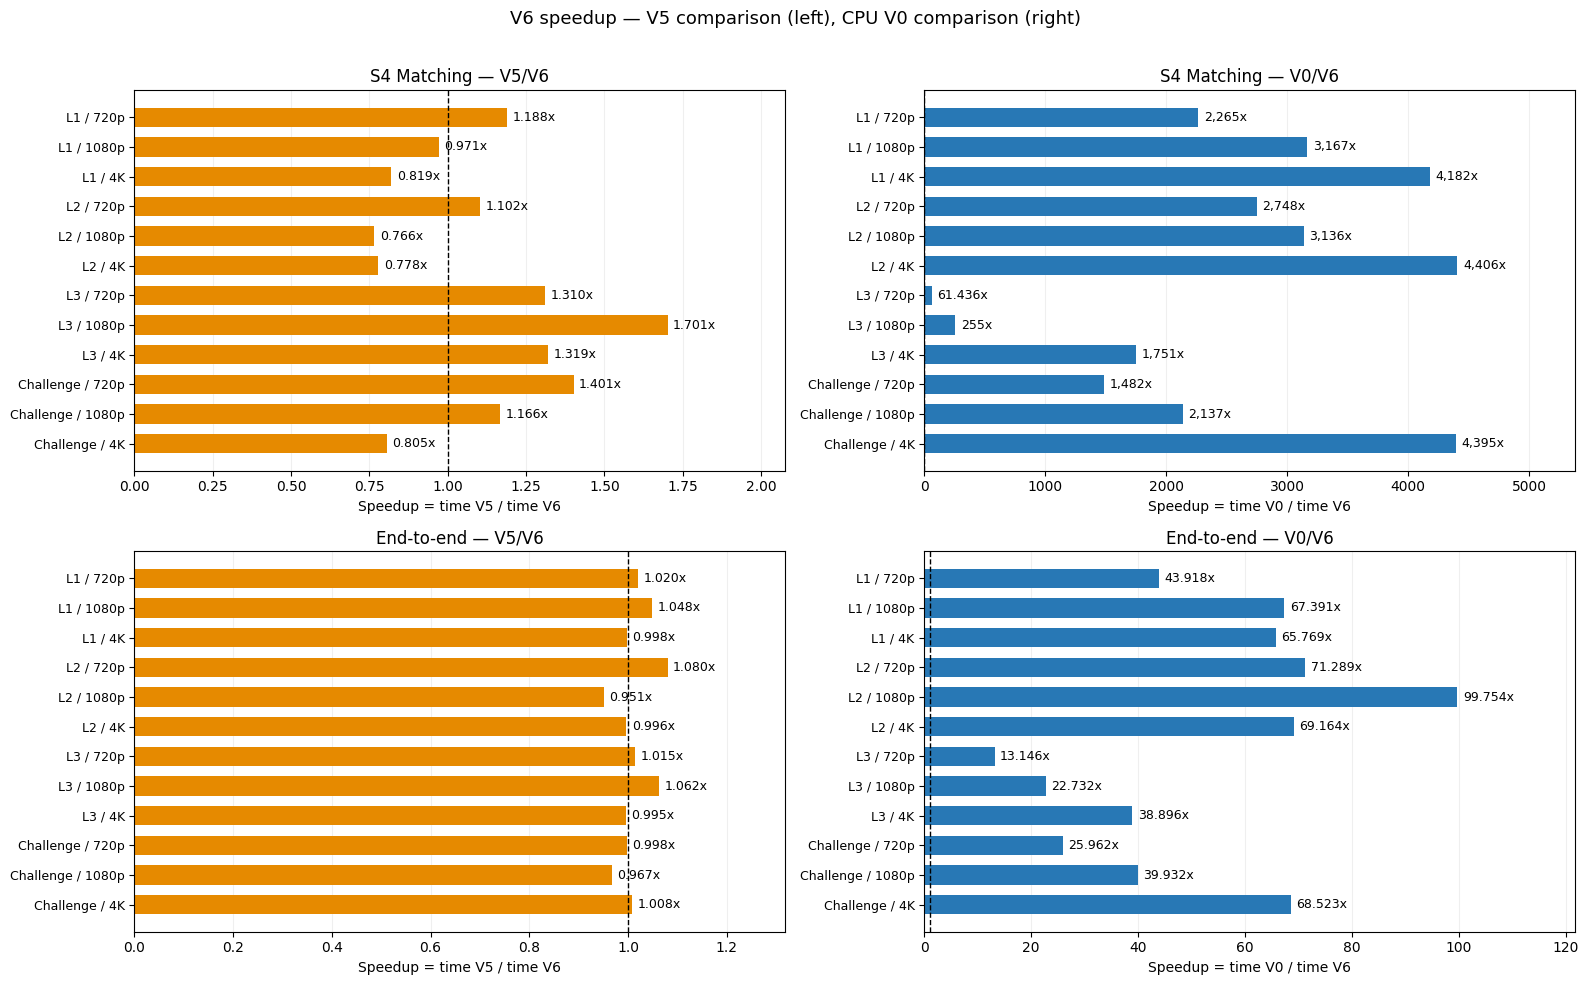

In [11]:
# V6_RESULT_PLOT: one figure, with independent scales for the two comparisons.
if not valid.empty:
    fig,axes = plt.subplots(2,2,figsize=(16,10))
    indexed = valid.set_index('case')
    def case_label(case):
        return (case.replace('location1_','L1 / ').replace('location2_','L2 / ')
                .replace('location3_','L3 / ').replace('challenge_','Challenge / ')
                .replace('small_720p','720p').replace('medium_1080p','1080p')
                .replace('large_4k','4K'))
    for row,(metric,title) in enumerate([('match','S4 Matching'),('end_to_end','End-to-end')]):
        for column,version,color in [(0,5,'#e68a00'),(1,0,'#2878b5')]:
            ax = axes[row,column]
            values = indexed[f'v{version}_over_v6_{metric}_speedup'].dropna()
            positions = list(range(len(values)))
            ax.barh(positions,values.to_numpy(),color=color,height=0.65)
            ax.set_yticks(positions)
            ax.set_yticklabels([case_label(case) for case in values.index],fontsize=9)
            ax.invert_yaxis()
            ax.axvline(1,color='black',linestyle='--',linewidth=1)
            ax.set_xlim(0,max(1.0,float(values.max()) if len(values) else 1.0)*1.22)
            ax.set_title(f'{title} — V{version}/V6')
            ax.set_xlabel(f'Speedup = time V{version} / time V6')
            ax.grid(axis='x',alpha=0.2)
            ax.set_axisbelow(True)
            for position,value in enumerate(values):
                label = f'{value:.3f}x' if version==5 or value<100 else f'{value:,.0f}x'
                ax.annotate(label,(value,position),xytext=(4,0),textcoords='offset points',
                            va='center',fontsize=9)
    fig.suptitle('V6 speedup — V5 comparison (left), CPU V0 comparison (right)',fontsize=13)
    plt.tight_layout(rect=(0,0,1,0.97)); plt.show()
else:
    print('No verified case to plot; inspect correctness/failure logs.')


### 6.3. Panorama đại diện và cặp challenge

Chỉ hiển thị kết quả V6 ở Medium cho từng địa điểm và cặp khó. Ảnh đầy đủ V0/V5/V6 ở mọi độ phân giải vẫn được lưu trong thư mục kết quả. Ảnh xem trước được thu nhỏ để notebook gọn, không thay ảnh dùng kiểm chứng.

Nếu cặp khó thất bại, giữ status và đường dẫn log, giải thích dựa trên ảnh/matches/homography thực tế. Không đoán nguyên nhân từ status, không xem việc hai bản cùng thất bại là panorama đã đúng.

**location1_medium_1080p — pass**

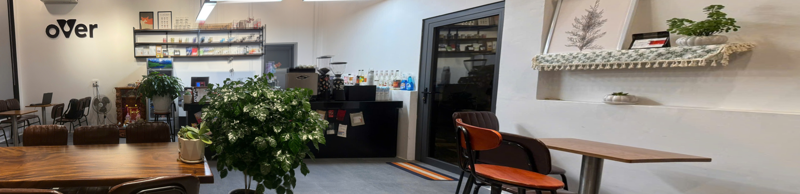

**location2_medium_1080p — pass**

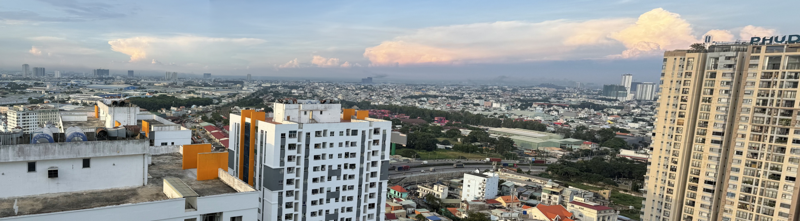

**location3_medium_1080p — pass**

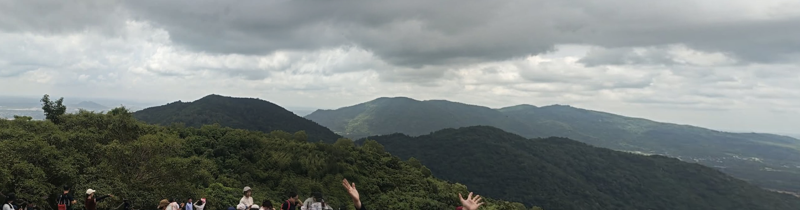

**challenge_medium_1080p — pass**

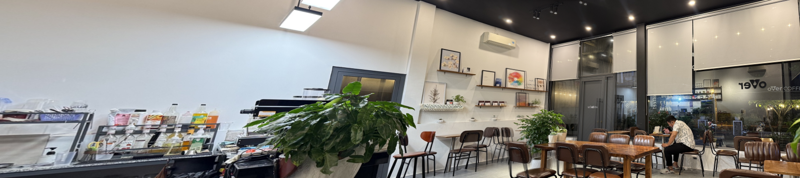

In [12]:
gallery = summary[summary.case.str.endswith('medium_1080p')]
for _,row in gallery.iterrows():
    display(Markdown(f"**{row['case']} — {row['status']}**"))
    report_path = RESULT_DIR/f"{row['case']}_v6.json"
    report = json.loads(report_path.read_text(encoding='utf-8')) if report_path.is_file() else {}
    path = Path(report.get('panorama',{}).get('path',''))
    if report.get('status')=='ok' and path.is_file():
        with PILImage.open(path) as original:
            preview = original.copy()
        preview.thumbnail((800,450))
        display(preview)
    else:
        print('No panorama:',report.get('error','missing output'))
    if row['status']!='pass':
        print('Inspect:',RESULT_DIR/f"{row['case']}_verification.log")

### 6.4. Profile cùng một case ở V5 và V6

Mặc định profile `location1_large_4k`; đổi `PROFILE_CASE` để kiểm tra case khác. Các lượt profiler chạy riêng từng version để đọc tên kernel và chi phí thực hiện, không thay cho benchmark xen kẽ. Report lưu riêng theo case/version.


In [13]:
PROFILE_CASE = 'location1_large_4k'
for version in (5,6):
    run([sys.executable,TOOLS_DIR/'profile.py','--run-dir',RESULT_DIR,
         '--version',version,'--case',PROFILE_CASE])
    manifest_path = RESULT_DIR/'profiling'/PROFILE_CASE/f'profile_v{version}.json'
    manifest = json.loads(manifest_path.read_text(encoding='utf-8'))
    print('Version:',version,'| case:',manifest.get('case'),'| profiling:',manifest['status'])
    if manifest['status']=='collected':
        print(Path(manifest['summary']).read_text(encoding='utf-8',errors='replace'))


$ /usr/bin/python3 src/tools/v6/profile.py --run-dir reports/v6_benchmark/20261128T050247957349Z/comparison --version 5 --case location1_large_4k
$ nsys profile --trace=cuda --sample=none --cpuctxsw=none --force-overwrite=true -o reports/v6_benchmark/20261128T050247957349Z/comparison/profiling/location1_large_4k/location1_large_4k_v5 build/benchmark_v6_pair dataset/location1/large_4k/1.jpg dataset/location1/large_4k/2.jpg reports/v6_benchmark/20261128T050247957349Z/comparison/profiling/location1_large_4k/location1_large_4k_v5.png 5 5 reports/v6_benchmark/20261128T050247957349Z/comparison/profiling/location1_large_4k/location1_large_4k_v5_diagnostic_timing.json
GPU: Tesla T4 version=5 runs=5
Generating '/tmp/nsys-report-cf3c.qdstrm'

[1/1] [0%                          ] location1_large_4k_v5.nsys-rep
[1/1] [0%                          ] location1_large_4k_v5.nsys-rep
[1/1] [===================81%      ] location1_large_4k_v5.nsys-rep
[1/1] [========================100%] location1_large_

## 7. Nhận xét

Kết quả được đo trên Tesla T4, mỗi phiên bản chạy một warm-up và năm lượt đo. V5/V6 chạy xen kẽ trong cùng process; thời gian trong bảng là trung bình của năm lượt, kèm minimum để đối chiếu mức dao động.

Cả 12 ca đều qua kiểm chứng. Test S4 xác nhận nearest index, best/second-best và ordered matches đúng với bản tham chiếu. Trong bảng kiểm chứng ảnh thật, sai số chiếu homography và sai lệch pixel giữa V5/V6 đều bằng 0. So với V0, sai số chiếu bằng 0, RGB lệch tối đa 1 mức và MAE khoảng 0,000003–0,000007. Như vậy, việc đổi cách chia việc của S4 vẫn giữ kết quả trong dung sai đã đặt.

S4 nhanh hơn V5 ở 7/12 ca, với speedup từ 0,766× đến 1,701×. Cải thiện rõ nhất là L3/1080p: thời gian giảm từ 0,178 ms xuống 0,105 ms, đạt 1,701×. Cả ba độ phân giải của L3 đều nhanh hơn. Ngược lại, L2/1080p tăng từ 0,804 ms lên 1,050 ms, chỉ đạt 0,766×; L1/4K, L2/4K và Challenge/4K cũng chậm hơn. Một warp/query vì thế chưa đem lại lợi ích đồng đều trên bộ dữ liệu này.

Về cách triển khai, V6 chia phép so sánh của một query cho 32 lane, nhưng thêm bước shuffle để gộp top-2. Tile descriptor ở V6 được bốn query trong block dùng chung, trong khi V5 dùng chung cho 128 query; mỗi tile vẫn cần hai lần đồng bộ block. Đây là các chi phí có thể làm giảm lợi ích của việc chia việc trong warp. Output Nsight Systems hiện có chưa đủ để xác định riêng mức ảnh hưởng của đồng bộ, truy cập bộ nhớ hay register pressure, nên chưa thể chốt nguyên nhân chậm ở từng ca.

End-to-end nhanh hơn ở 6/12 ca, speedup nằm trong khoảng 0,951×–1,080×. L2/720p giảm từ 27,907 ms xuống 25,834 ms, nhưng S4 chỉ tiết kiệm khoảng 0,054 ms trong tổng mức giảm 2,073 ms. Tương tự, L3/1080p tiết kiệm khoảng 0,074 ms ở S4, còn toàn pipeline giảm 2,044 ms. Các stage giữ nguyên và phần chi phí ngoài S4 cũng thay đổi thời gian, nên không thể quy toàn bộ mức tăng tốc end-to-end cho tối ưu warp/query.

Baseline V5 cho thấy S4 chỉ chiếm khoảng 0,53%–3,46% tổng thời gian kernel. Profiling L1/4K cũng cho thấy `nearest_tiled_kernel` chiếm 0,8% thời gian kernel, trong khi `warp_blend_v5_kernel` chiếm 44,8%. S4 có thể cải thiện ở một số ca, nhưng chưa phải bottleneck chính của V5 trong lần đo này; do đó lợi ích toàn pipeline bị giới hạn. V6 giữ đúng ý tưởng một warp/query và bảo toàn kết quả, nhưng số đo hiện tại chưa cho thấy hiệu năng tốt hơn V5 trên toàn bộ bộ dữ liệu.
